# 04 — Rolling linear factor model

Fits rolling orthogonal factor models, reports attribution and diagnostics, and tests whether the AI-close extension is more useful for AI-exposed assets than for non-AI controls.

Reusable implementation and configuration: `src/factor_lens/linear_model.py`.


In [1]:
from pathlib import Path
import sys

project_root = Path.cwd().resolve()
while project_root != project_root.parent and not (project_root / "src" / "factor_lens").exists():
    project_root = project_root.parent
if not (project_root / "src" / "factor_lens").exists():
    raise RuntimeError("Open this notebook from the repository root or a subfolder.")
sys.path.insert(0, str(project_root / "src"))


In [2]:
from factor_lens import linear_model as pipeline

res = pipeline.get_results()
pipeline.make_figures(res)
pipeline.print_report(res)


FileNotFoundError: factor_lens_local/factors/factors_v1__clean_v1__yahoo_2016-01-01_2026-10-01_v1/factors_raw.parquet

## Prediction diagnostics

Run the first function for basket plots or change the ticker for a single-stock view.


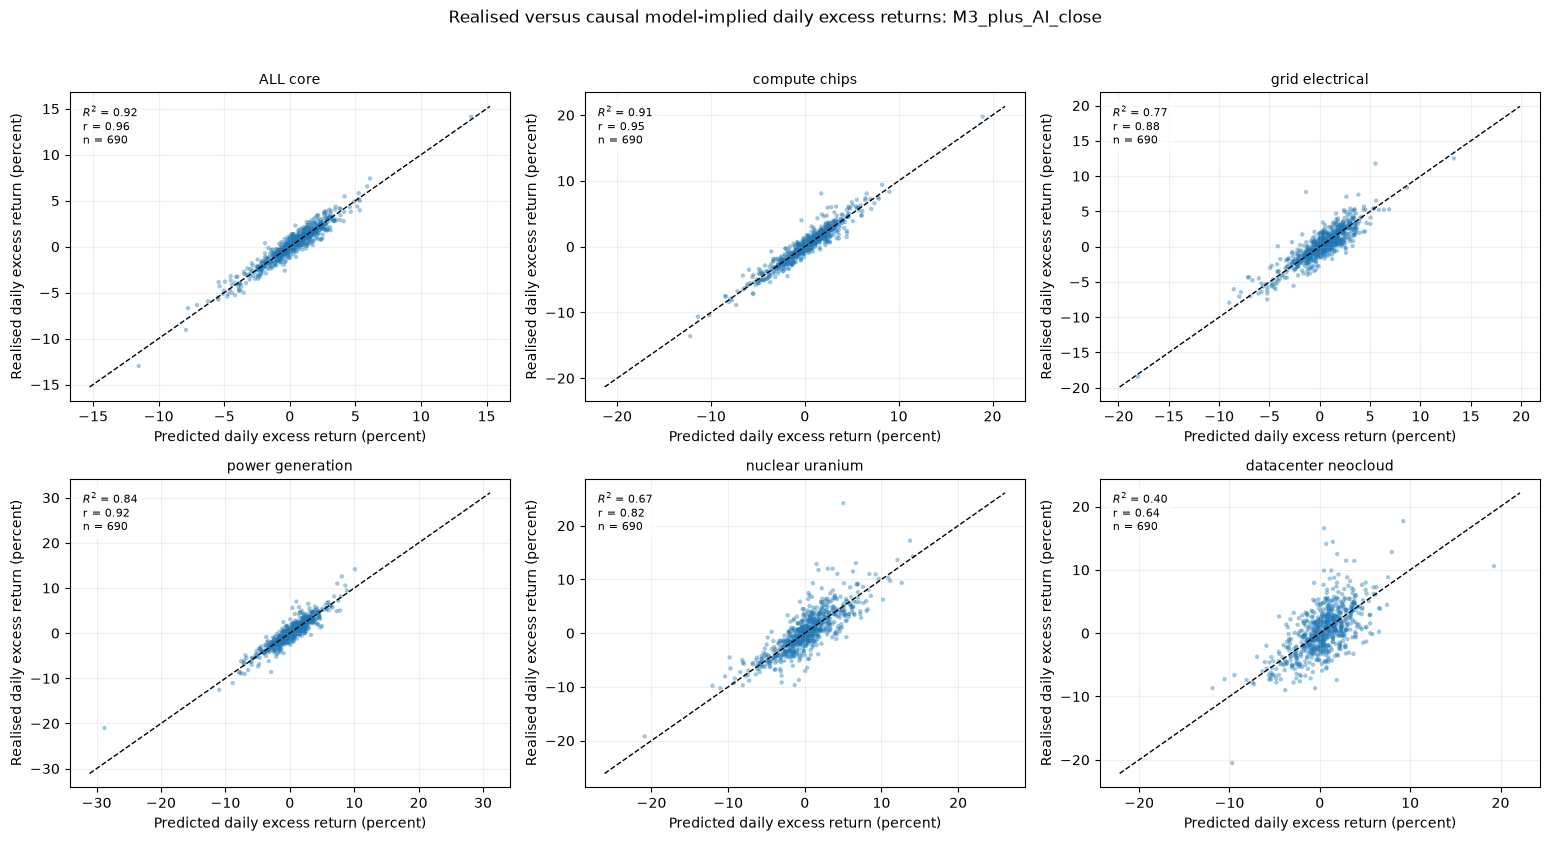

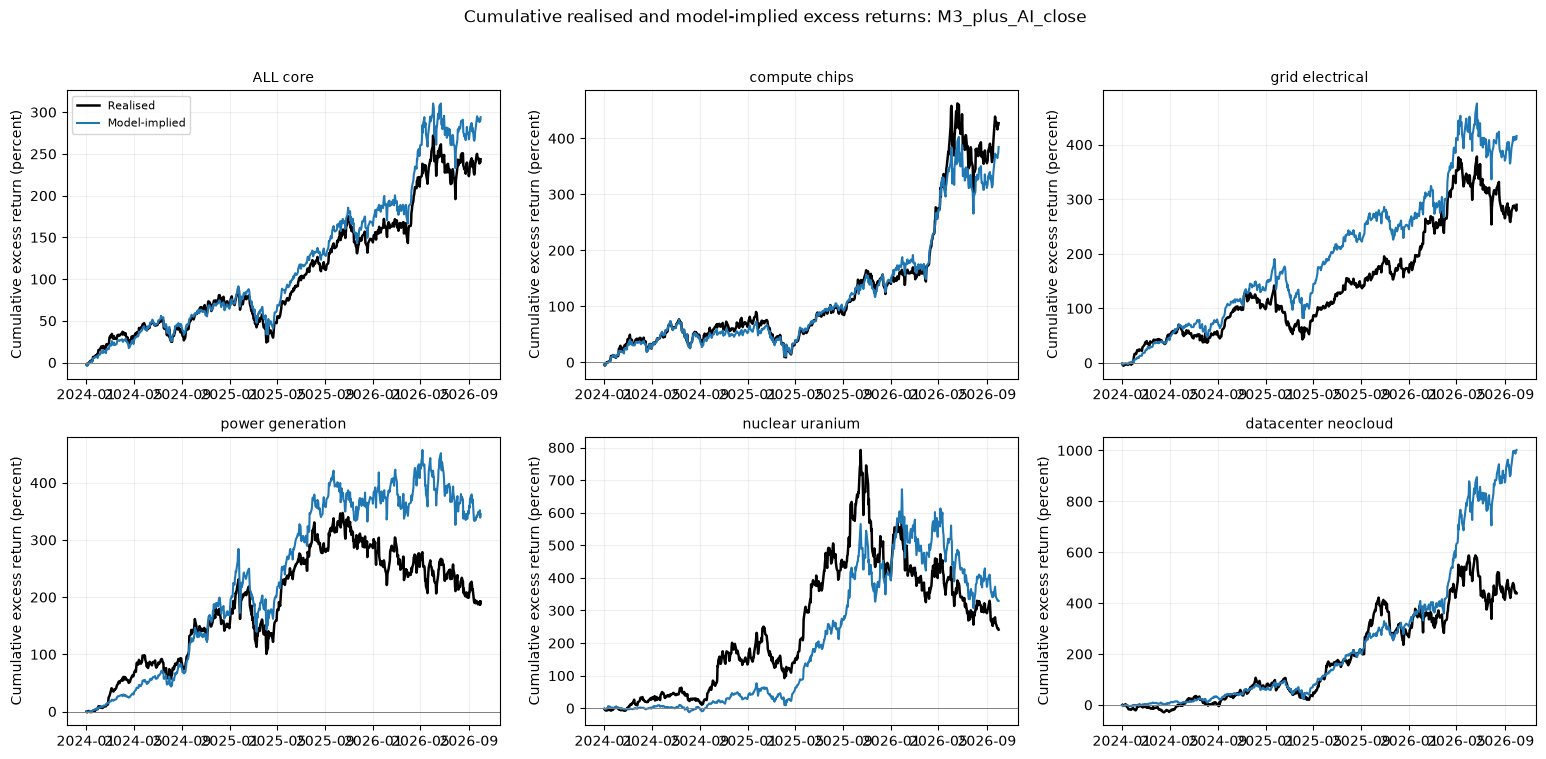

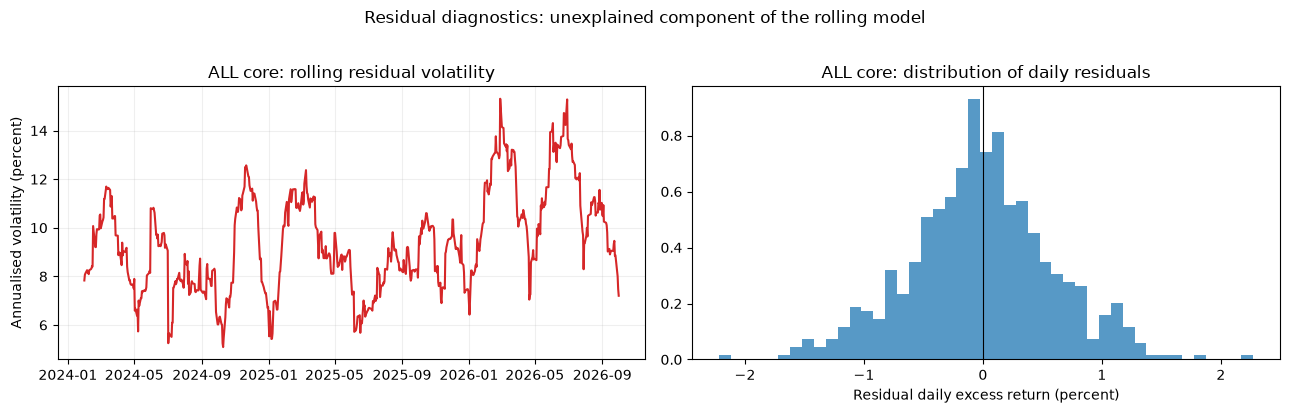

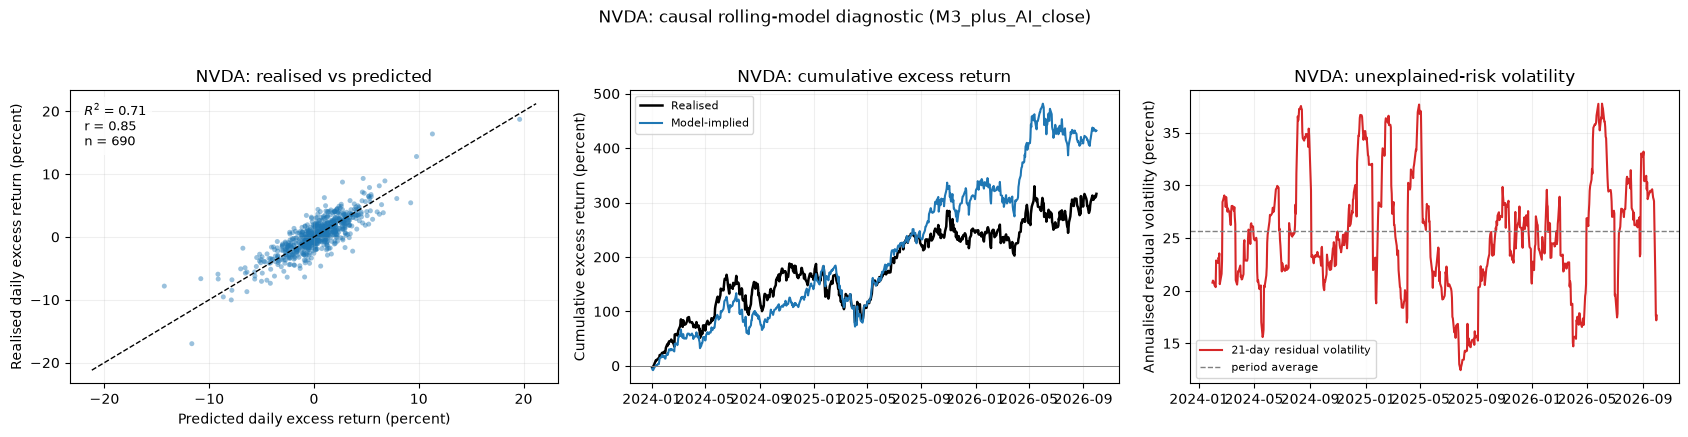

In [3]:
pipeline.plot_prediction_diagnostics(res)
stock_diagnostic = pipeline.plot_stock_prediction_diagnostics(res, 'NVDA')


## AI-factor specificity placebo test

This compares the M2-to-M3 holdout improvement for AI-close stocks and a pre-declared non-AI control group. Direct holdings by the added-factor ETFs are marked in the stock-level chart.


AI-factor specificity check: holdout incremental R2 of M3 over M2
Added block: SEMI, SOFT, ROBO, MOM
A positive AI-close gain with a near-zero/smaller control gain supports specificity. It does not establish causation.


,target,n_days,r2_base,r2_oos,increment,d_lo,d_hi,sig
11,AI_close_test,690,0.803,0.841,0.039,0.024,0.055,True
12,non_AI_control_test,690,0.557,0.701,0.144,0.087,0.220,True


,target,test_group,r2_base,r2_oos,increment,d_lo,d_hi,sig,direct_factor_holding
30,ORCL,AI_close,0.244,0.388,0.144,0.052,0.245,True,True
26,MSFT,AI_close,0.364,0.497,0.133,0.070,0.200,True,True
13,NVDA,AI_close,0.592,0.713,0.121,0.073,0.169,True,True
15,AVGO,AI_close,0.475,0.587,0.112,0.078,0.149,True,True
27,GOOGL,AI_close,0.373,0.397,0.024,-0.020,0.058,False,True
28,AMZN,AI_close,0.493,0.515,0.022,-0.012,0.059,False,True
29,META,AI_close,0.365,0.343,-0.023,-0.073,0.012,False,True
53,PG,non_AI_control,0.271,0.367,0.096,0.035,0.152,True,False
56,JNJ,non_AI_control,0.287,0.364,0.077,0.043,0.117,True,False
57,JPM,non_AI_control,0.337,0.390,0.053,0.023,0.094,True,False


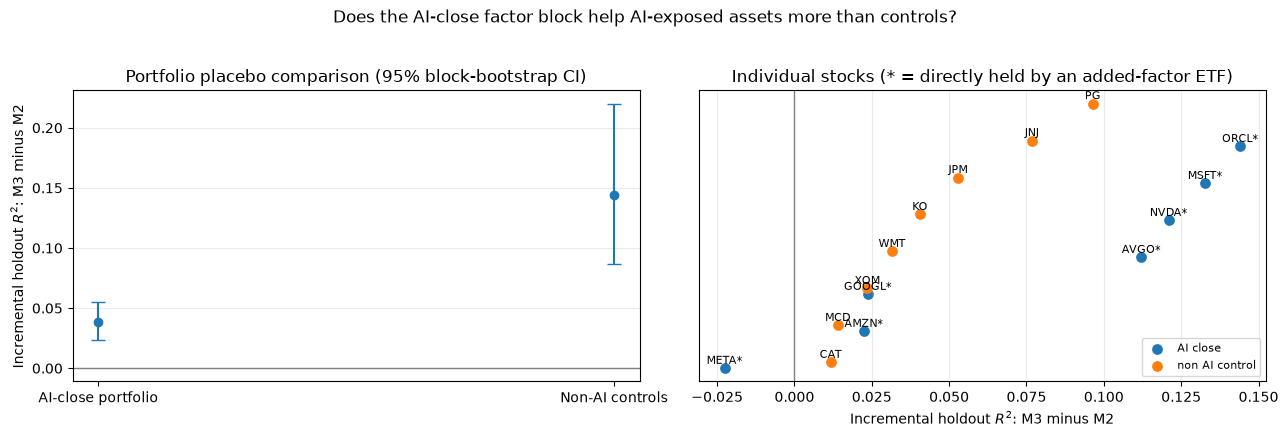

In [4]:
ai_placebo_portfolios, ai_placebo_stocks = pipeline.ai_factor_placebo_test(res)
